**BEATS PER MINUTE**

>Proyecto

>Predecir los beats por minuto de un determinado grupo de canciones tomando como referencia el dataset dado.

>Descripción

>El conjunto de datos obtenido contiene la predicción de los beats por minuto, por tal motivo, el aprendizaje es supervisado.

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, make_scorer, r2_score, mean_squared_error
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
#Carga de los datos y creación de la copia de seguridad del dataset
data = pd.read_csv("C:/Users/PcDroide/Documents/MasterUE_IA/Machine_Learning/Proyecto/Proyecto_BPS_Files/Datasets/train.csv")
data_set_original = data.copy()



**ANÁLISIS DEL CONJUNTO DE DATOS**



In [3]:
# Verificación de datos falatantes y nulos
vacio = data.isna().sum()
nulo = data.isnull().sum()
print(f"La cantidad de líneas vacías por columna es: \n{vacio}")
print(f"\nLa cantidad de valores nulos es: \n{nulo}")

La cantidad de líneas vacías por columna es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64

La cantidad de valores nulos es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64


In [4]:
# Verificación de filas duplicadas
print("          Filas Duplicadas")
display(data[data.duplicated(keep=False)])

          Filas Duplicadas


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [5]:
# Evaluación estadística del dataset
print("\nInformación del dataset:\n")
print(data.info())
print("\nDescripción estadística del dataset:\n")
print(data.describe())


Información del dataset:

<class 'pandas.DataFrame'>
RangeIndex: 524164 entries, 0 to 524163
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id                         524164 non-null  int64  
 1   RhythmScore                524164 non-null  float64
 2   AudioLoudness              524164 non-null  float64
 3   VocalContent               524164 non-null  float64
 4   AcousticQuality            524164 non-null  float64
 5   InstrumentalScore          524164 non-null  float64
 6   LivePerformanceLikelihood  524164 non-null  float64
 7   MoodScore                  524164 non-null  float64
 8   TrackDurationMs            524164 non-null  float64
 9   Energy                     524164 non-null  float64
 10  BeatsPerMinute             524164 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 44.0 MB
None

Descripción estadística del dataset:

                  id    RhythmScore 

In [6]:
# Forma del dataset
filas, columnas = data.shape
print(f"\nForma del Dataset\nFilas: {filas}\nColumnas: {columnas}")


Forma del Dataset
Filas: 524164
Columnas: 11


In [7]:
# Condición: La energía, los beats por minuto y la duración de la canción no deben tener valores negativos.
# Así validamos que los datos no generen inconsistencias.
filtro_energy = (data["Energy"] < 0)
filtro_beat = (data["BeatsPerMinute"] < 0)
filtro_duracion = (data["TrackDurationMs"] <= 0)

print("Filas que contienen valores negativos de energía ,de beats o de TrackDuration")
display(data[filtro_energy])
display(data[filtro_beat])
display(data[filtro_duracion])

Filas que contienen valores negativos de energía ,de beats o de TrackDuration


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


>Las verificaiones anteriores nos indican que la integridad del conjunto de los datos es buena y que, en cuanto a forma, se puede utilizar.  Lo siguiente es verificar las variables que lo componen.

**EVALUACIÓN DE LAS VARIABLES**

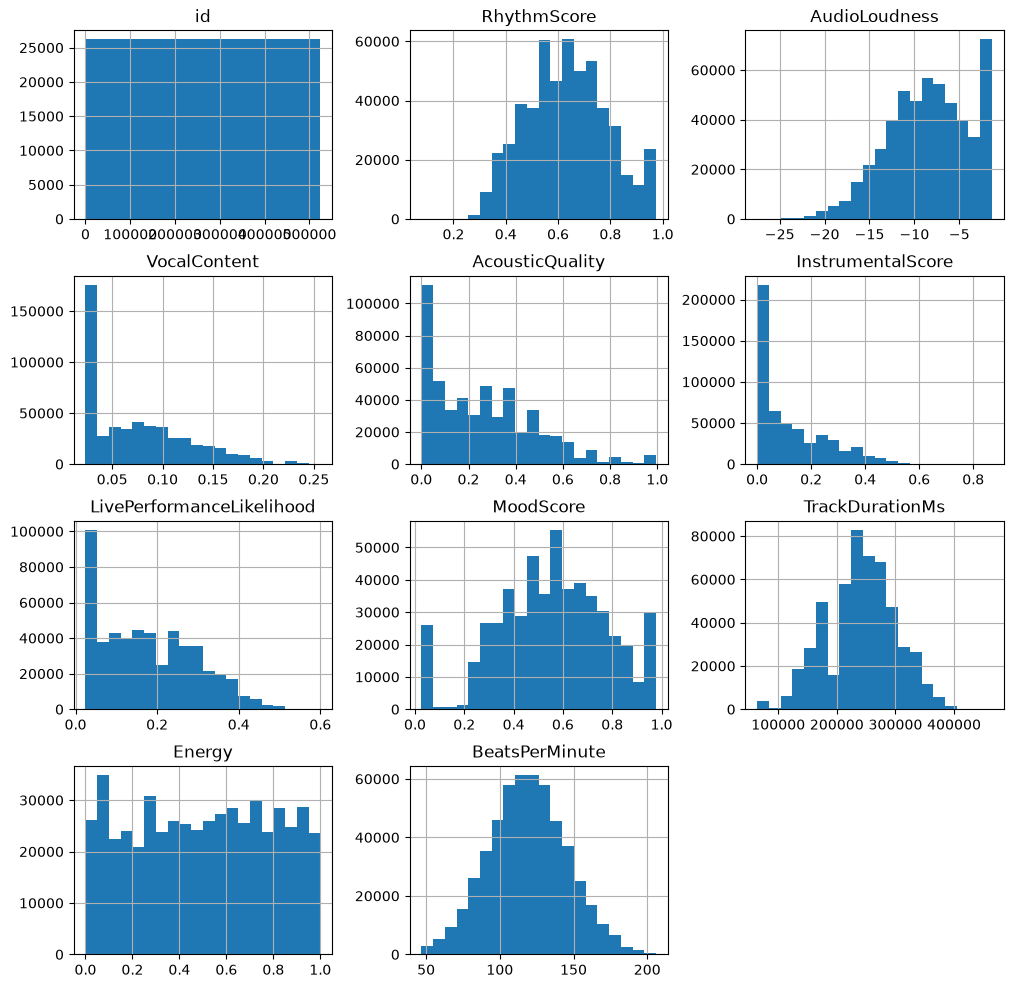

In [8]:
# Histograma de todas las variables numéricas
data.hist(figsize=(12, 12), bins=20)
plt.show()

>Tras la verificación visual de los valores de cada variable vemos que puede haber presencia de valores que estén fuera de la distribución, por lo que se procede a graficar los datos outliners en cada variable.  Para esto se separan las variables de acuerdo a su rango para ver los gráficos de una mejor manera.


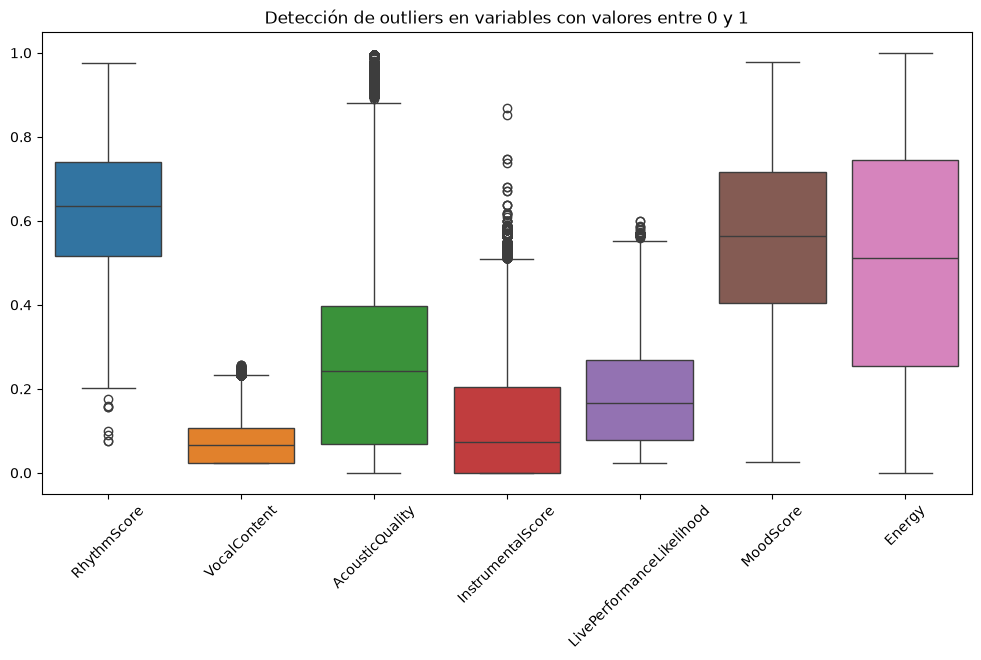

In [9]:
# Gráfica de outliners de las variables que tienen valores entre 0 y 1.
cols_df = ["RhythmScore", "VocalContent", "AcousticQuality", "InstrumentalScore", "LivePerformanceLikelihood", "MoodScore", "Energy"]
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[cols_df])
plt.xticks(rotation=45)  
plt.title("Detección de outliers en variables con valores entre 0 y 1")
plt.show()

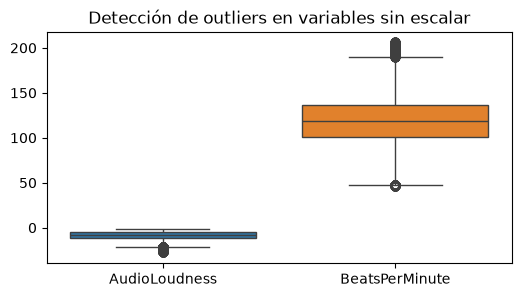

In [10]:
# Gráfica de valores para las variables con valores grandes
cols_df_2 = ["AudioLoudness", "BeatsPerMinute"]
plt.figure(figsize=(6, 3))
sns.boxplot(data=data[cols_df_2]) 
plt.title("Detección de outliers en variables sin escalar")
plt.show()

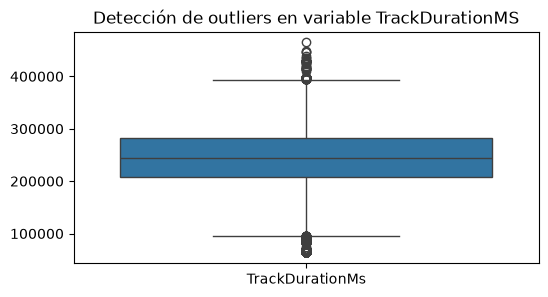

In [10]:
# Gráfico de la variable con los valores más altos
cols_3 = ["TrackDurationMs"] 
plt.figure(figsize=(6, 3))
sns.boxplot(data=data[cols_3])
plt.title("Detección de outliers en variable TrackDurationMS")
plt.show()

>Las gráficas nos muestran la presencia de outliners en las variables y para verificar qué tanto pueden afectar se procede a sumar la cantidad y qué tan representativo es el total de outliners en cada variable.

In [11]:
# Verificación de outliners usando la medida de IQR para ver la cantidad de datos fuera de la tendencia
# Cálculo del IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

# Límiter dl índice intercuartílico.
inf = Q1 - 1.5*IQR
sup = Q3 + 1.5*IQR
cantidad_outliers = pd.DataFrame({
    "Total": (
        (data < (inf)) | (data > (sup))
    ).sum(),
    "Porcentaje (%)": (
        ((data < (inf)) | (data > (sup))).mean() * 100
    ).round(2),
})

# Muestra todas las variables ordenadas de mayor a menor cantidad de outliers
print(cantidad_outliers.sort_values(by="Total", ascending=False))

                           Total  Porcentaje (%)
AcousticQuality             6746            1.29
TrackDurationMs             4267            0.81
InstrumentalScore           2845            0.54
BeatsPerMinute              2141            0.41
AudioLoudness               1770            0.34
VocalContent                1245            0.24
LivePerformanceLikelihood    129            0.02
RhythmScore                    8            0.00
id                             0            0.00
MoodScore                      0            0.00
Energy                         0            0.00


>Las variables presentan outliners pero, por la cantidad que hay no se considera que vayan a fectar el rendimiento del modelo, además, como la integridad de os datos fue buen, se considera que estos valores fuera de rango responden a meidas reales.  

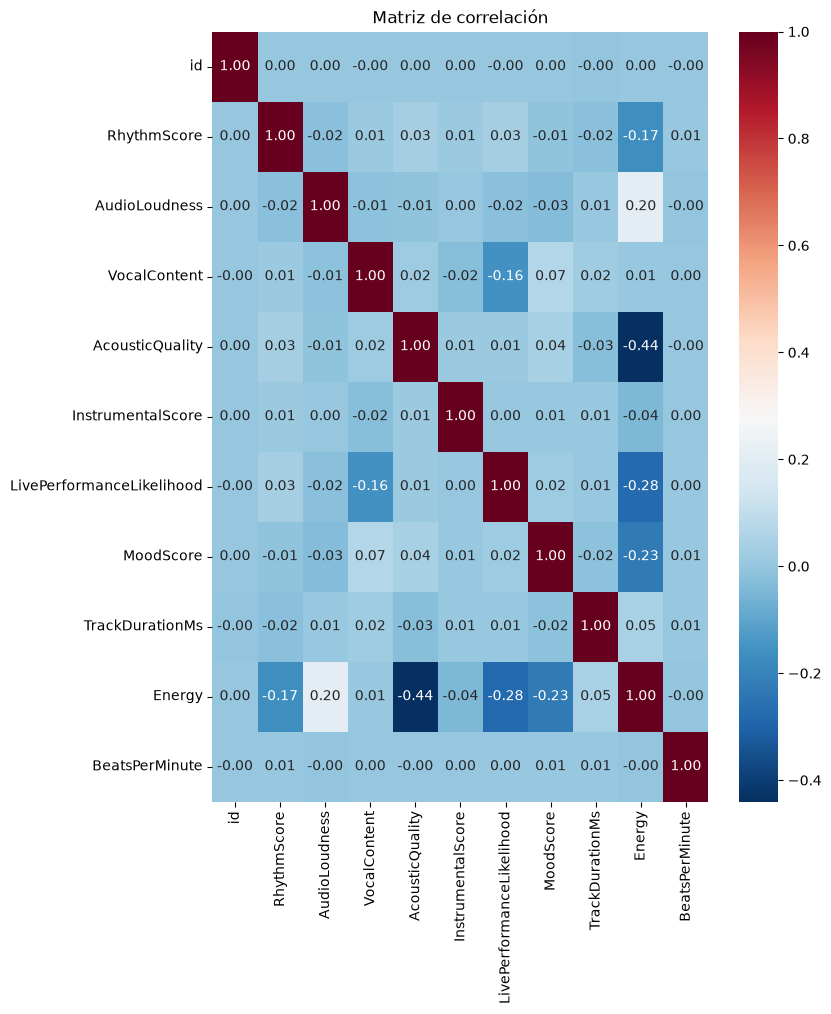

In [12]:
# Visualización de la correlación entre variables
plt.figure(figsize=(8, 10))
sns.heatmap(data.corr(method="spearman"), annot=True, fmt='.2f', cmap='RdBu_r')
plt.title('Matriz de correlación')
plt.show()

In [13]:
# Análisis de parejas de variables más correladas entre sí.  Se Imprimen las primeras columnas buscando las variables que
# más correlación tienen.
correlation_matrix = data.corr()
corr_pairs = correlation_matrix.abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()
corr_pairs.columns = ['Variable 1', 'Variable 2', 'Correlación']
#orr_pairs = corr_pairs[corr_pairs['Variable 1'] != corr_pairs['Variable 2']]
print(corr_pairs.head(15))

                   Variable 1                 Variable 2  Correlación
0                          id                         id     1.000000
1               AudioLoudness              AudioLoudness     1.000000
2                 RhythmScore                RhythmScore     1.000000
3             AcousticQuality            AcousticQuality     1.000000
4                VocalContent               VocalContent     1.000000
5             TrackDurationMs            TrackDurationMs     1.000000
6                   MoodScore                  MoodScore     1.000000
7   LivePerformanceLikelihood  LivePerformanceLikelihood     1.000000
8           InstrumentalScore          InstrumentalScore     1.000000
9              BeatsPerMinute             BeatsPerMinute     1.000000
10                     Energy                     Energy     1.000000
11            AcousticQuality                     Energy     0.418184
12                     Energy            AcousticQuality     0.418184
13  LivePerformanceL

>El análisis de la correlación entre las variables nos muestra que las variables de entrada tienen muy poca correlación conla variable de salida y que la variable "Energy" tiene una correlación lineal, entre moderada y baja, con las demás variables.

Terminada la etapa de análisis y verificación del conjunto de datos y las variables, se va a separar el conjunto de datos con una proporción de 75% para train y 25% para test, ya que, hay muestras suficientes (más de quinentas mil) para que esta distribución se a decuada.

Luego de separar los datos se va a realizar una estandarización de todas las variables, excepto la variable "id" porque esta variable no aporta información para la predicción de los beats por minuto de las canciones.

In [14]:
# Separación del conjuto de datos y estandarización de las variables

X = data.drop(columns=["id", "BeatsPerMinute"])
y = data["BeatsPerMinute"]

# Separación de los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Estandarización de las variables

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled = scaler.fit_transform(X_train_scaled)
X_test_scaled = X_test.copy()
X_test_scaled = scaler.transform(X_test_scaled)